# **Deep Learning Project: Street View Housing Number Digit Recognition**

# **Marks: 60**

--------------
## **Context**
--------------

One of the most interesting tasks in deep learning is to recognize objects in natural scenes. The ability to process visual information using machine learning algorithms can be very useful as demonstrated in various applications.

The SVHN dataset contains over 600,000 labeled digits cropped from street-level photos. It is one of the most popular image recognition datasets. It has been used in neural networks created by Google to improve the map quality by automatically transcribing the address numbers from a patch of pixels. The transcribed number with a known street address helps pinpoint the location of the building it represents.

----------------
## **Objective**
----------------

Our objective is to predict the number depicted inside the image by using Artificial or Fully Connected Feed Forward Neural Networks and Convolutional Neural Networks. We will go through various models of each and finally select the one that is giving us the best performance.

-------------
## **Dataset**
-------------
Here, we will use a subset of the original data to save some computation time. The dataset is provided as a .h5 file. The basic preprocessing steps have been applied on the dataset.

## **Mount the drive**

Let us start by mounting the Google drive. You can run the below cell to mount the Google drive.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## **Importing the necessary libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Activation, BatchNormalization, Flatten
from tensorflow.keras.losses import categorical_crossentropy
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

import warnings
warnings.simplefilter("ignore")

%matplotlib inline

**Let us check the version of tensorflow.**

In [ ]:
print(tf.__version__)

2.19.0


## **Load the dataset**

- Let us now load the dataset that is available as a .h5 file.
- Split the data into the train and the test dataset.

In [ ]:
import h5py

#import .h5 file
ds = h5py.File('/content/drive/MyDrive/trainings/MIT/notebook/elective_project/SVHN_single_grey1.h5', 'r')

#split the dataset
X_train = ds['X_train'][:]
X_test = ds['X_test'][:]
y_train = ds['y_train'][:]
y_test = ds['y_test'][:]

#close the imported file for memory usage
ds.close()

Check the number of images in the training and the testing dataset.

In [ ]:
#Calculate & print total number of image
tot_num_images = len(X_train) + len(X_test) + len(y_train) + len(y_test)
print("Total number of images:", str(tot_num_images), "100 %", sep="         ")

#Print number of image and their ratio in regard to the total number of images
print('\n'"X_train :",str(len(X_train)),"images","                       ",(len(X_train)/tot_num_images)*100,"%", sep=" ")
print('\n'"X_test :",str(len(X_test)),"images","                        ",(len(X_test)/tot_num_images)*100,"%", sep=" ")
print('\n'"y_train :",str(len(y_train)),"images","                       ",(len(y_train)/tot_num_images)*100,"%", sep=" ")
print('\n'"y_test :",str(len(y_test)),"images","                        ",(len(y_test)/tot_num_images)*100,"%", sep=" ")

Total number of images:         120000         100 %

X_train : 42000 images                         35.0 %

X_test : 18000 images                          15.0 %

y_train : 42000 images                         35.0 %

y_test : 18000 images                          15.0 %


**Observation:**



*   The training & testing datasets contain 120,000 images
*   The training datasets represent 70% of the images (2 x 35 %)
*   The testing datasets reprent 30% of the images (2 x 15 %)




## **Visualizing images**

- Use X_train to visualize the first 10 images.
- Use Y_train to print the first 10 labels.

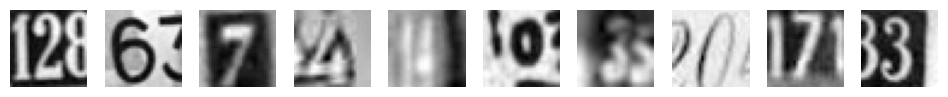

Labels for each of the above image:[2 6 7 4 4 0 3 0 7 3]


In [ ]:
#Define the plot size
plt.figure(figsize = (12, 1))

#Plot the first 10 images of X_train
for i in range(10):

    plt.subplot(1, 10, i+1)

    plt.imshow(X_train[i], cmap = "gray")

    plt.axis('off')

plt.show()

#Print the first 10 labes from y_train
print('Labels for each of the above image:' + str((y_train[0:10])))


## **Data preparation**

- Print the shape and the array of pixels for the first image in the training dataset.
- Normalize the train and the test dataset by dividing by 255.
- Print the new shapes of the train and the test dataset.
- One-hot encode the target variable.

In [ ]:
#Choose the image by index (0 = 1rst)
n = 0
#Print the shape of the for image
print("Shape of the image number:",str(n+1),X_train[n].shape, sep=" ")
#Print the array
print('\n',"Array:",str(n+1),X_train[n], sep=" ")

Shape of the image number: 1 (32, 32)

 Array: 1 [[ 33.0704  30.2601  26.852  ...  71.4471  58.2204  42.9939]
 [ 25.2283  25.5533  29.9765 ... 113.0209 103.3639  84.2949]
 [ 26.2775  22.6137  40.4763 ... 113.3028 121.775  115.4228]
 ...
 [ 28.5502  36.212   45.0801 ...  24.1359  25.0927  26.0603]
 [ 38.4352  26.4733  23.2717 ...  28.1094  29.4683  30.0661]
 [ 50.2984  26.0773  24.0389 ...  49.6682  50.853   53.0377]]


### **Normalize the train and the test data**

In [ ]:
#Reshape the dataset to a vector2 for the ANN
X_train = X_train.reshape(X_train.shape[0], 1024)
X_test = X_test.reshape(X_test.shape[0], 1024)
#Print shapes
X_train.shape, X_test.shape

((42000, 1024), (18000, 1024))

In [ ]:
#Compute max pixel value of the training dataset
val_max_orig = np.max(X_train)
#Normalize the images
X_train = X_train / 255
X_test = X_test / 255
#Compute max pixel value of the training dataset after normalization
val_max_normalized = np.max(X_train)
#Print both original max pixel value and normalized pixel value
print("Original max pixel value :",val_max_orig, sep=' ')
print("New max pixel value :",val_max_normalized, sep=' ')

Original max pixel value : 254.9745
New max pixel value : 0.9999


Print the shapes of Training and Test data

In [ ]:
#Print the shape of the training data
print('\n',"Shape of the image number",str(n+1),"from the training set:",X_train[0].shape, sep=" ")
print("Array of the normalized image number",str(n+1),X_train[0],"from the training set", sep=" ")
#Print the shape of the test data
print('\n',"Shape of the image number",str(n+1),"from the test set:",X_test[0].shape, sep=" ")
print("Array of the normalized image number",str(n+1),X_test[0],"from the test set", sep=" ")


 Shape of the image number 1 from the training set: (1024,)
Array of the normalized image number 1 [0.12968785 0.11866706 0.10530196 ... 0.19477727 0.19942354 0.20799099] from the training set

 Shape of the image number 1 from the test set: (1024,)
Array of the normalized image number 1 [0.15905097 0.18349686 0.19206432 ... 0.43143883 0.4360851  0.44780627] from the test set


### **One-hot encode output**

In [ ]:
#Encode the output
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)
#Print the output shape
y_train.shape, y_test.shape
y_test

array([[0., 1., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 1., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 1., 0., 0.],
       [0., 0., 0., ..., 0., 0., 1.],
       [0., 0., 1., ..., 0., 0., 0.]])

**Observation:**


*   Images shape is 32x32 pixels
*   Original pixel value range is 255
*   y_train & y_test are now encoded rather than labeled




## **Model Building**

Now that we have done the data preprocessing, let's build an ANN model.

### Fix the seed for random number generators

In [ ]:
#Define a seed variable to ensure a common value for all necessary libraries
seed = 42
#Set seed for Numpy
np.random.seed(seed)
#Import Random lib
import random
#Set seed for Random
random.seed(seed)
#Set seed for TensorFlow
tf.random.set_seed(seed)

### **Model Architecture**
- Write a function that returns a sequential model with the following architecture:
 - First hidden layer with **64 nodes and the relu activation** and the **input shape = (1024, )**
 - Second hidden layer with **32 nodes and the relu activation**
 - Output layer with **activation as 'softmax' and number of nodes equal to the number of classes, i.e., 10**
 - Compile the model with the **loss equal to categorical_crossentropy, optimizer equal to Adam(learning_rate = 0.001), and metric equal to 'accuracy'**. Do not fit the model here, just return the compiled model.
- Call the nn_model_1 function and store the model in a new variable.
- Print the summary of the model.
- Fit on the train data with a **validation split of 0.2, batch size = 128, verbose = 1, and epochs = 20**. Store the model building history to use later for visualization.

### **Build and train an ANN model as per the above mentioned architecture.**

In [ ]:
#Define function for the ANN model
def nn_model_1():
  model = Sequential()                                          #create an instance of the ANN model
  model.add(Dense(64, activation='relu', input_shape=(1024,)))  #first layer with 'input_shape'
  model.add(Dense(32, activation='relu'))
  model.add(Dense(10, activation='softmax'))                    #Output layer
  #Compile the model
  model.compile(optimizer=Adam(learning_rate = 0.001),loss='categorical_crossentropy', metrics=['accuracy'])

  return model
#Store the model in a variable
model_1 = nn_model_1()
#Print summary
model_1.summary()
#Fit the model to the training datasets
fit_history_model_1 = model_1.fit(X_train, y_train, validation_split=0.2, verbose=1, epochs=20, batch_size=128)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 68,010 (265.66 KB)

 Trainable params: 68,010 (265.66 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.1088 - loss: 2.3082 - val_accuracy: 0.1744 - val_loss: 2.2324
Epoch 2/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.2135 - loss: 2.1556 - val_accuracy: 0.3065 - val_loss: 1.9384
Epoch 3/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.3158 - loss: 1.9163 - val_accuracy: 0.3844 - val_loss: 1.7683
Epoch 4/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.4275 - loss: 1.6879 - val_accuracy: 0.5104 - val_loss: 1.4989
Epoch 5/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5228 - loss: 1.4552 - val_accuracy: 0.5558 - val_loss: 1.3696
Epoch 6/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5636 - loss: 1.3518 - val_accuracy: 0.5798 - val_loss: 1.3064
Epoch 7/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.5877 - loss: 1.2884 - val_accuracy: 0.6018 - val_loss: 1.2553
Epoch 8/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.6060 - loss: 1.2421 - val_accuracy: 0.

### **Plot the Training and Validation Accuracies and write down your Observations.**

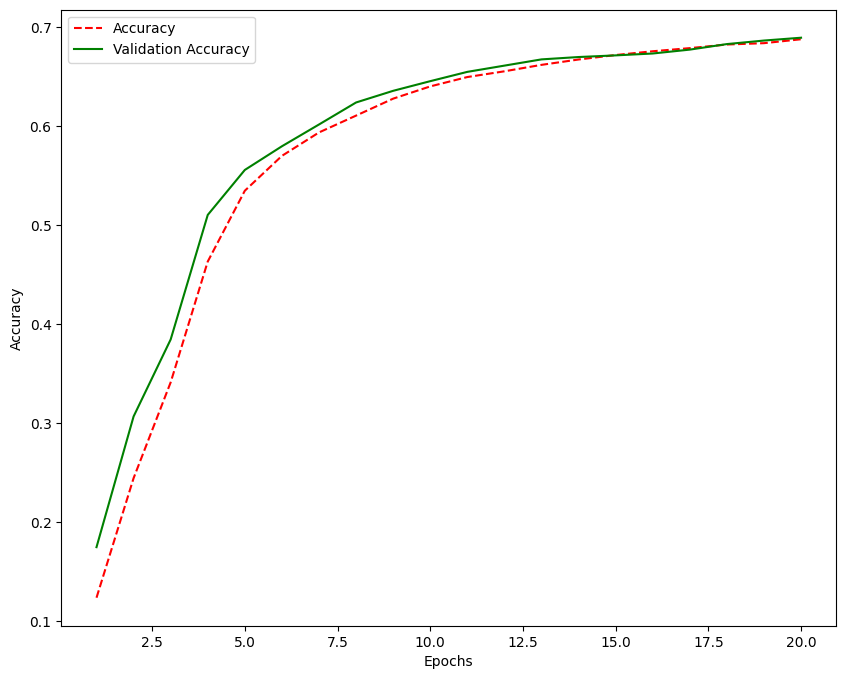

In [ ]:
#Store performance metrics in a variable
dict_history_m1 = fit_history_model_1.history
#Define the range of the X axis of the plot matching the number of epochs
num_epochs = [i for i in range(1, 21)]
#Define the size of the plot
plt.figure(figsize=(10, 8))
#Create the curve representation of the values
plt.plot(num_epochs, dict_history_m1['accuracy'], '--', label='Accuracy', color='red')
plt.plot(num_epochs, dict_history_m1['val_accuracy'], label='Validation Accuracy', color='green')
#Define the name of the axis
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
#Show the legend of the plot
plt.legend()
#Show plot
plt.show()


**Observations:_______**



*   The model show major improvement in accuracy until the 6th epoch
*   The model keep improving performances until the 20th epoch
*   The accuracy and the validation accuracy curves get very close after the 15th epoch wich means that the model give the most reliable results at this stage
*   Both accuracy and validation accuracy don't rise above 68% showing there's room for improvement in the model performance



Let's build one more model with higher complexity and see if we can improve the performance of the model.

First, we need to clear the previous model's history from the Keras backend. Also, let's fix the seed again after clearing the backend.

In [ ]:
from tensorflow.keras import backend  #Import backend to clear session
backend.clear_session()               #Clean model history

### **Second Model Architecture**
- Write a function that returns a sequential model with the following architecture:
 - First hidden layer with **256 nodes and the relu activation** and the **input shape = (1024, )**
 - Second hidden layer with **128 nodes and the relu activation**
 - Add the **Dropout layer with the rate equal to 0.2**
 - Third hidden layer with **64 nodes and the relu activation**
 - Fourth hidden layer with **64 nodes and the relu activation**
 - Fifth hidden layer with **32 nodes and the relu activation**
 - Add the **BatchNormalization layer**
 - Output layer with **activation as 'softmax' and number of nodes equal to the number of classes, i.e., 10**
 -Compile the model with the **loss equal to categorical_crossentropy, optimizer equal to Adam(learning_rate = 0.0005), and metric equal to 'accuracy'**. Do not fit the model here, just return the compiled model.
- Call the nn_model_2 function and store the model in a new variable.
- Print the summary of the model.
- Fit on the train data with a **validation split of 0.2, batch size = 128, verbose = 1, and epochs = 30**. Store the model building history to use later for visualization.

### **Build and train the new ANN model as per the above mentioned architecture**

In [ ]:
#Define function for the ANN model
def nn_model_2():
  model = Sequential()                                              #create an instance of the ANN model
  model.add(Dense(256, activation='relu', input_shape=(1024,)))     #first layer with 'input_shape'
  model.add(Dense(128, activation='relu'))
  model.add(Dropout(rate=0.2))                                      #Deactivate 20% of the nodes randomly each epochs
  model.add(Dense(64, activation='relu'))
  model.add(Dense(64, activation='relu'))
  model.add(Dense(32, activation='relu'))
  model.add(BatchNormalization())                                   #Normalize the output of the previous layer
  model.add(Dense(10, activation='softmax'))                        #Output layer
#Compile the model
  model.compile(optimizer=Adam(learning_rate = 0.0005),loss='categorical_crossentropy', metrics=['accuracy'])
  return model
#Store the model in a variable
model_2 = nn_model_2()
#Print summary
model_2.summary()
#Fit the model to the training datasets
fit_history_model_2 = model_2.fit(X_train, y_train, validation_split=0.2, verbose=1, epochs=30, batch_size=128)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       262,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 310,250 (1.18 MB)

 Trainable params: 310,186 (1.18 MB)

 Non-trainable params: 64 (256.00 B)

Epoch 1/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.1023 - loss: 2.4061 - val_accuracy: 0.1060 - val_loss: 2.3020
Epoch 2/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.1194 - loss: 2.2898 - val_accuracy: 0.1962 - val_loss: 2.1986
Epoch 3/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.2746 - loss: 1.9807 - val_accuracy: 0.3888 - val_loss: 1.7676
Epoch 4/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.4377 - loss: 1.6278 - val_accuracy: 0.5345 - val_loss: 1.3841
Epoch 5/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.5540 - loss: 1.3582 - val_accuracy: 0.6151 - val_loss: 1.2025
Epoch 6/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.6128 - loss: 1.2027 - val_accuracy: 0.6657 - val_loss: 1.0532
Epoch 7/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.6429 - loss: 1.1117 - val_accuracy: 0.6544 - val_loss: 1.0762
Epoch 8/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.6621 - loss: 1.0561 - val_accu

### **Plot the Training and Validation Accuracies and write down your Observations.**

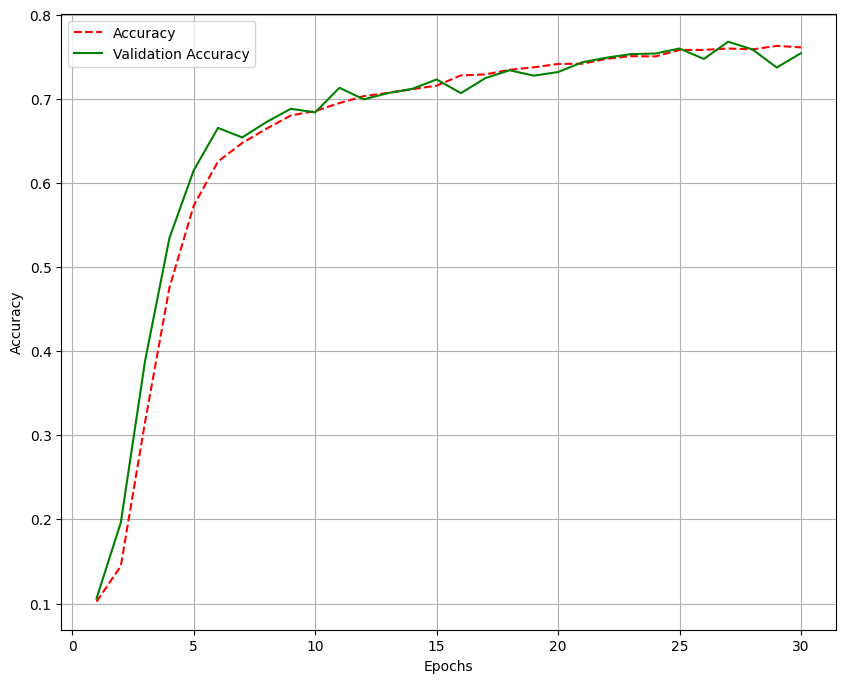

In [ ]:
#Store performance metrics in a variable
dict_history_m2 = fit_history_model_2.history
#Define range for the x axis according to epoch numbers
num_epochs = [i for i in range(1, 31)]
#Set plot size to 1000x800 px
plt.figure(figsize=(10, 8))
#Plot accuracies
plt.plot(num_epochs, dict_history_m2['accuracy'], '--', label='Accuracy', color='red')
plt.plot(num_epochs, dict_history_m2['val_accuracy'], label='Validation Accuracy', color='green')
#Create grid for better value identification along the curves
plt.grid()
#Set the labels
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
#Set the legend
plt.legend()
#Show the plot
plt.show()


**Observations:_______**



*   Max accuracy is ~77%  
*   The validation accuracy is higher than the training accuracy until 10th epoch
*   The validation accuracy plot depict minor dropouts
*   Both the validation accuracy & training accuracy are coherent


## **Predictions on the test data**

- Make predictions on the test set using the second model.
- Print the obtained results using the classification report and the confusion matrix.
- Final observations on the obtained results.

In [ ]:
#Prediction on the test dataset
test_pred = model_2.predict(X_test)
test_pred = np.argmax(test_pred, axis = -1)

563/563 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


**Note:** Earlier, we noticed that each entry of the target variable is a one-hot encoded vector but to print the classification report and confusion matrix, we must convert each entry of y_test to a single label.

In [ ]:
#
y_test = np.argmax(y_test, axis = -1)
y_test

array([1, 7, 2, ..., 7, 9, 2])

### **Print the classification report and the confusion matrix for the test predictions. Write your observations on the final results.**

              precision    recall  f1-score   support

           0       0.74      0.79      0.77      1814
           1       0.70      0.83      0.76      1828
           2       0.85      0.75      0.79      1803
           3       0.74      0.72      0.73      1719
           4       0.85      0.75      0.79      1812
           5       0.70      0.74      0.72      1768
           6       0.72      0.75      0.74      1832
           7       0.76      0.81      0.78      1808
           8       0.75      0.71      0.73      1812
           9       0.77      0.69      0.73      1804

    accuracy                           0.75     18000
   macro avg       0.76      0.75      0.75     18000
weighted avg       0.76      0.75      0.75     18000



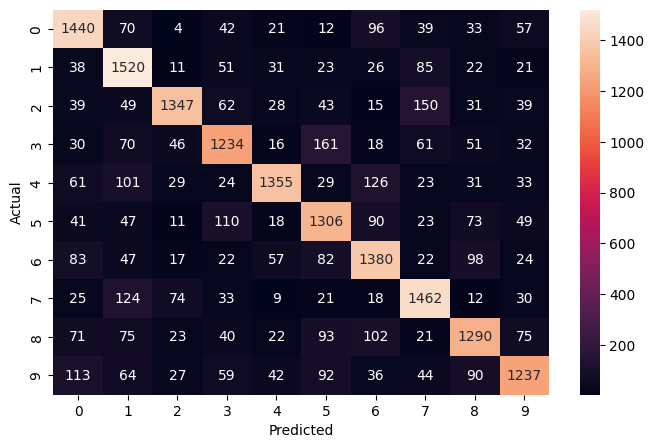

In [ ]:
#Import report and confusion matrix modules
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
#Print the classification report
print(classification_report(y_test, test_pred))
#Compute confusion matrix
cm = confusion_matrix(y_test, test_pred)
#Define the plot size
plt.figure(figsize=(8,5))
#Plot the confusion matrix using seaborn heatmap
sns.heatmap(cm, annot = True,  fmt = 'd', xticklabels = list(range(10)), yticklabels = list(range(10)))
#Define the axis' labels
plt.xlabel('Predicted')
plt.ylabel('Actual')
#Show plot
plt.show()



**Final Observations:__________**

*  The model's performance are balanced exept for two categories: 3 & 5
*  The higher precision score is visible on categorie 4
*  Precision & Recall are balanced
*  Categories such as 5, 6 & 7 have a larger amount of false positive
*  Categories such as 3 & 1 have a larger amount of false negative

## **Using Convolutional Neural Networks**

### **Load the dataset again and split the data into the train and the test dataset.**

In [ ]:
#import h5py library for file reading
import h5py
#import .h5 file
ds = h5py.File('/content/drive/MyDrive/trainings/MIT/notebook/elective_project/SVHN_single_grey1.h5', 'r')
#split the dataset
X_train = ds['X_train'][:]
X_test = ds['X_test'][:]
y_train = ds['y_train'][:]
y_test = ds['y_test'][:]
#close the imported file for memory usage
ds.close()

Check the number of images in the training and the testing dataset.

In [ ]:
#Calculate & print total number of image
tot_num_images = len(X_train) + len(X_test) + len(y_train) + len(y_test)
print("Total number of images:", str(tot_num_images), "100 %", sep="         ")

#Print number of image and their ratio in regard to the total number of images
print('\n'"X_train :",str(len(X_train)),"images","                       ",(len(X_train)/tot_num_images)*100,"%", sep=" ")
print('\n'"X_test :",str(len(X_test)),"images","                        ",(len(X_test)/tot_num_images)*100,"%", sep=" ")
print('\n'"y_train :",str(len(y_train)),"images","                       ",(len(y_train)/tot_num_images)*100,"%", sep=" ")
print('\n'"y_test :",str(len(y_test)),"images","                        ",(len(y_test)/tot_num_images)*100,"%", sep=" ")

Total number of images:         120000         100 %

X_train : 42000 images                         35.0 %

X_test : 18000 images                          15.0 %

y_train : 42000 images                         35.0 %

y_test : 18000 images                          15.0 %


**Observation:**

*   The training & testing datasets contain 120,000 images
*   The training datasets represent 70% of the images
*   The testing datasets reprent 30% of the images

## **Data preparation**

- Print the shape and the array of pixels for the first image in the training dataset.
- Reshape the train and the test dataset because we always have to give a 4D array as input to CNNs.
- Normalize the train and the test dataset by dividing by 255.
- Print the new shapes of the train and the test dataset.
- One-hot encode the target variable.

In [ ]:
#Print shapes
X_train.shape, X_test.shape

((42000, 32, 32), (18000, 32, 32))

Reshape the dataset to be able to pass them to CNNs. Remember that we always have to give a 4D array as input to CNNs

In [ ]:
#Reshape X_train and X_test to array of dimension 4
X_train = X_train.reshape(X_train.shape[0], 32, 32, 1)
X_test = X_test.reshape(X_test.shape[0], 32, 32, 1)
#Print shape
X_train.shape, X_test.shape

((42000, 32, 32, 1), (18000, 32, 32, 1))

Normalize inputs from 0-255 to 0-1

In [ ]:
#Normalize images
X_train /= 255
X_test /= 255
#Print X_train max pixel value to check normalisation result
X_train.max()

np.float32(0.9999)

Print New shape of Training and Test

In [ ]:
#Print the shape of training and test sets
print("X_train shape :",X_train.shape, sep='  ')
print("X_test shape :",X_test.shape, sep='   ')

X_train shape :  (42000, 32, 32, 1)
X_test shape :   (18000, 32, 32, 1)


### **One-hot encode the labels in the target variable y_train and y_test.**

In [ ]:
#Encode labels to binary
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

**Observation:**



*   Image size is 32x32 pixels
*   X_train & X_test are normalized
*   X_train & X_test are reshaped to 4D array for the CNN model purpose
*   y_train & y_test are now binary encoded



## **Model Building**

Now that we have done data preprocessing, let's build a CNN model.
Fix the seed for random number generators

In [ ]:
#Define a seed value
seed = 36
#Set seed for numpy
np.random.seed = seed
#Import Random library
import random
#Set seed for random
random.seed(seed)
#Set seed for TensorFlow
tf.random.set_seed(seed)

### **Model Architecture**
- **Write a function** that returns a sequential model with the following architecture:
 - First Convolutional layer with **16 filters and the kernel size of 3x3**. Use the **'same' padding** and provide the **input shape = (32, 32, 1)**
 - Add a **LeakyRelu layer** with the **slope equal to 0.1**
 - Second Convolutional layer with **32 filters and the kernel size of 3x3 with 'same' padding**
 - Another **LeakyRelu** with the **slope equal to 0.1**
 - A **max-pooling layer** with a **pool size of 2x2**
 - **Flatten** the output from the previous layer
 - Add a **dense layer with 32 nodes**
 - Add a **LeakyRelu layer with the slope equal to 0.1**
 - Add the final **output layer with nodes equal to the number of classes, i.e., 10** and **'softmax' as the activation function**
 - Compile the model with the **loss equal to categorical_crossentropy, optimizer equal to Adam(learning_rate = 0.001), and metric equal to 'accuracy'**. Do not fit the model here, just return the compiled model.
- Call the function cnn_model_1 and store the output in a new variable.
- Print the summary of the model.
- Fit the model on the training data with a **validation split of 0.2, batch size = 32, verbose = 1, and epochs = 20**. Store the model building history to use later for visualization.

### **Build and train a CNN model as per the above mentioned architecture.**

In [ ]:
#Import necessary module for the CNN model
from tensorflow.keras.layers import LeakyReLU, Conv2D, MaxPooling2D
#Create model definition
def cnn_model_1():
  model = Sequential()                                                        #create an instance of the ANN model
  model.add(Conv2D(16, (3, 3), padding='same', input_shape=(32, 32, 1)))      #first layer with 'input_shape'
  model.add(LeakyReLU(alpha=0.1))
  model.add(Conv2D(32, (3, 3), padding='same'))
  model.add(LeakyReLU(alpha=0.1))
  model.add(MaxPooling2D(pool_size=(2, 2)))
  model.add(Flatten())                                                        #Flatten the output of the previous layer

  model.add(Dense(32))
  model.add(LeakyReLU(alpha=0.1))
  model.add(Dense(10, activation='softmax'))                                  #Output layer

#Compile the model
  model.compile(optimizer=Adam(learning_rate = 0.001),loss='categorical_crossentropy', metrics=['accuracy'])
  return(model)

#Store the model in a variable
cnn_model_1 = cnn_model_1()
#Print summary
cnn_model_1.summary()
#Fit the model to the training datasets
fit_history_cnn_model_1 = cnn_model_1.fit(X_train, y_train, validation_split=0.2, verbose=1, epochs=20, batch_size=32)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │       262,176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 267,306 (1.02 MB)

 Trainable params: 267,306 (1.02 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 68s 63ms/step - accuracy: 0.4195 - loss: 1.6673 - val_accuracy: 0.8218 - val_loss: 0.6248
Epoch 2/20
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 82s 63ms/step - accuracy: 0.8215 - loss: 0.6170 - val_accuracy: 0.8471 - val_loss: 0.5406
Epoch 3/20
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 80s 62ms/step - accuracy: 0.8556 - loss: 0.5044 - val_accuracy: 0.8590 - val_loss: 0.5074
Epoch 4/20
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 84s 64ms/step - accuracy: 0.8728 - loss: 0.4371 - val_accuracy: 0.8648 - val_loss: 0.4908
Epoch 5/20
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 79s 61ms/step - accuracy: 0.8890 - loss: 0.3826 - val_accuracy: 0.8674 - val_loss: 0.4851
Epoch 6/20
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 65s 62ms/step - accuracy: 0.9022 - loss: 0.3394 - val_accuracy: 0.8675 - val_loss: 0.4959
Epoch 7/20
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 67s 64ms/step - accuracy: 0.9125 - loss: 0.2991 - val_accuracy: 0.8643 - val_loss: 0.5139
Epoch 8/20
1050/1050 ━━━━━━━━━━━━━━━━━━━━ 65s 62ms/step - accuracy: 0.9251 -

### **Plot the Training and Validation Accuracies and Write your observations.**

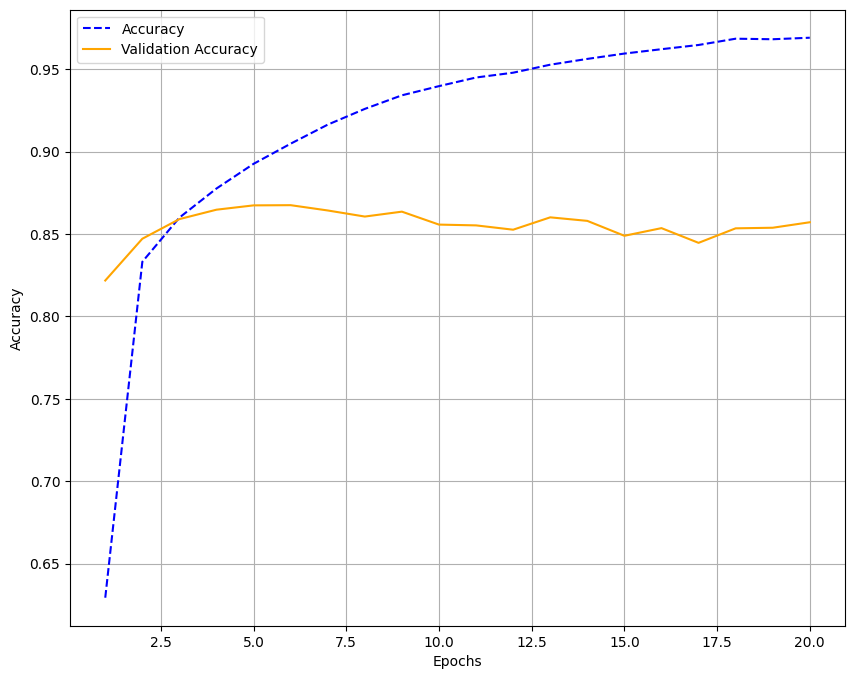

In [ ]:
#Storing model performance metrics history in a variable
dict_history_cnn_m1 = fit_history_cnn_model_1.history
#Define x axis range coherent to the number of epochs of the model
num_epochs = [i for i in range(1, 21)]
#Define plot size
plt.figure(figsize=(10, 8))
#Plot the accuracy values
plt.plot(num_epochs, dict_history_cnn_m1['accuracy'], '--', label='Accuracy', color='blue')
plt.plot(num_epochs, dict_history_cnn_m1['val_accuracy'], label='Validation Accuracy', color='orange')
#Create a grid for accurate value reading
plt.grid()
#Set labels
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
#Show Legend of the plot
plt.legend()
#Show plot
plt.show()


**Observations:__________**



*   The accuracy on the training dataset keep improving along the epochs
*   The validation dataset accuracy reach its peak at the 7th epoch and doesnt improve from there
*   The validation dataset accuracy value sits between ~0.82 & ~0.86
*   The model seems to overfit
*   The computational time is higher than the previous ANN models: ~ 65s / step

Let's build another model and see if we can get a better model with generalized performance.

First, we need to clear the previous model's history from the Keras backend. Also, let's fix the seed again after clearing the backend.

In [ ]:
#Import the backend module from TensorFlow
from tensorflow.keras import backend
#Clear memory from previous model
backend.clear_session()

### **Second Model Architecture**

- Write a function that returns a sequential model with the following architecture:
 - First Convolutional layer with **16 filters and the kernel size of 3x3**. Use the **'same' padding** and provide the **input shape = (32, 32, 1)**
 - Add a **LeakyRelu layer** with the **slope equal to 0.1**
 - Second Convolutional layer with **32 filters and the kernel size of 3x3 with 'same' padding**
 - Add **LeakyRelu** with the **slope equal to 0.1**
 - Add a **max-pooling layer** with a **pool size of 2x2**
 - Add a **BatchNormalization layer**
 - Third Convolutional layer with **32 filters and the kernel size of 3x3 with 'same' padding**
 - Add a **LeakyRelu layer with the slope equal to 0.1**
 - Fourth Convolutional layer **64 filters and the kernel size of 3x3 with 'same' padding**
 - Add a **LeakyRelu layer with the slope equal to 0.1**
 - Add a **max-pooling layer** with a **pool size of 2x2**
 - Add a **BatchNormalization layer**
 - **Flatten** the output from the previous layer
 - Add a **dense layer with 32 nodes**
 - Add a **LeakyRelu layer with the slope equal to 0.1**
 - Add a **dropout layer with the rate equal to 0.5**
 - Add the final **output layer with nodes equal to the number of classes, i.e., 10** and **'softmax' as the activation function**
 - Compile the model with the **categorical_crossentropy loss, adam optimizers (learning_rate = 0.001), and metric equal to 'accuracy'**. Do not fit the model here, just return the compiled model.
- Call the function cnn_model_2 and store the model in a new variable.
- Print the summary of the model.
- Fit the model on the train data with a **validation split of 0.2, batch size = 128, verbose = 1, and epochs = 30**. Store the model building history to use later for visualization.

### **Build and train the second CNN model as per the above mentioned architecture.**

In [ ]:
#Create the function for the model
def cnn_model_2():
  model = Sequential()                                                          #create an instance of the ANN model
  model.add(Conv2D(16, (3, 3), padding='same', input_shape=(32, 32, 1)))        #first layer with 'input_shape'
  model.add(LeakyReLU(alpha=0.1))                                               #Set the activation function to LeakyRelu
  model.add(Conv2D(32, (3, 3), padding='same'))
  model.add(LeakyReLU(alpha=0.1))
  model.add(MaxPooling2D(pool_size=(2, 2)))
  model.add(BatchNormalization())

  model.add(Conv2D(32, (3, 3), padding='same'))
  model.add(LeakyReLU(alpha=0.1))
  model.add(Conv2D(64, (3, 3), padding='same'))
  model.add(LeakyReLU(alpha=0.1))
  model.add(MaxPooling2D(pool_size=(2, 2)))
  model.add(BatchNormalization())

  model.add(Flatten())

  model.add(Dense(32))
  model.add(LeakyReLU(alpha=0.1))
  model.add(Dropout(rate=0.5))                                                  #Deactivate 50% of the nodes randomly each epochs

  model.add(Dense(10, activation='softmax'))

#Compile the model
  model.compile(optimizer=Adam(learning_rate = 0.001),loss='categorical_crossentropy', metrics=['accuracy'])
  return(model)

#Store the model in a variable
cnn_model_2 = cnn_model_2()
#Print summary
cnn_model_2.summary()
#Fit the model to the training datasets
fit_history_cnn_model_2 = cnn_model_2.fit(X_train, y_train, validation_split=0.2, verbose=1, epochs=30, batch_size=128)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16, 16, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 8, 8, 64)       │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       131,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 164,362 (642.04 KB)

 Trainable params: 164,170 (641.29 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 108s 401ms/step - accuracy: 0.3264 - loss: 1.9330 - val_accuracy: 0.2782 - val_loss: 2.3683
Epoch 2/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 106s 402ms/step - accuracy: 0.7772 - loss: 0.7226 - val_accuracy: 0.8148 - val_loss: 0.6240
Epoch 3/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 103s 392ms/step - accuracy: 0.8221 - loss: 0.5859 - val_accuracy: 0.8733 - val_loss: 0.4474
Epoch 4/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 106s 405ms/step - accuracy: 0.8450 - loss: 0.5123 - val_accuracy: 0.8861 - val_loss: 0.4101
Epoch 5/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 144s 413ms/step - accuracy: 0.8619 - loss: 0.4503 - val_accuracy: 0.8918 - val_loss: 0.3858
Epoch 6/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 104s 396ms/step - accuracy: 0.8727 - loss: 0.4156 - val_accuracy: 0.8781 - val_loss: 0.4340
Epoch 7/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 153s 438ms/step - accuracy: 0.8806 - loss: 0.3871 - val_accuracy: 0.8860 - val_loss: 0.4133
Epoch 8/30
263/263 ━━━━━━━━━━━━━━━━━━━━ 136s 415ms/step - accuracy: 0.8848 -

### **Plot the Training and Validation accuracies and write your observations.**

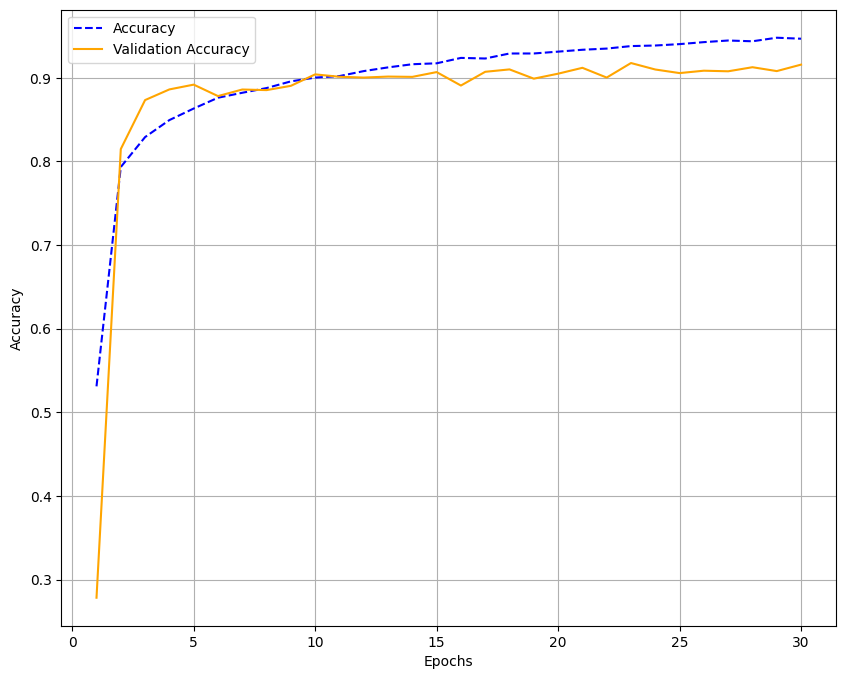

In [ ]:
#Storing model performance metrics history in a variable
dict_history_cnn_m2 = fit_history_cnn_model_2.history
#Define number of epoch regarding the model settings for the x axis of the plot
num_epochs = [i for i in range(1, 31)]
#Set the plot size to 1000x800 pixels
plt.figure(figsize=(10, 8))
#Plot accuracy values
plt.plot(num_epochs, dict_history_cnn_m2['accuracy'], '--', label='Accuracy', color='blue')
plt.plot(num_epochs, dict_history_cnn_m2['val_accuracy'], label='Validation Accuracy', color='orange')
#Create a grid
plt.grid()
#Set labels
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
#Show legend
plt.legend()
#Show plot
plt.show()


**Observations:________**

*   Accuracy on training data: ~95 %
*   Loss on training data: ~14.5 %
*   Accuracy on validation data: ~91 %
*   Loss on validation data: ~51 %

*   The model's performance improved
*   The model doesn't seems to overfit or underfit
*   The model computational time is high compare to the previous CNN model: ~107s / step

## **Predictions on the test data**

- Make predictions on the test set using the second model.
- Print the obtained results using the classification report and the confusion matrix.
- Final observations on the obtained results.

### **Make predictions on the test data using the second model.**

In [ ]:
#Prediction on the test dataset
test_pred = cnn_model_2.predict(X_test)
test_pred = np.argmax(test_pred, axis = -1)

563/563 ━━━━━━━━━━━━━━━━━━━━ 15s 27ms/step


**Note:** Earlier, we noticed that each entry of the target variable is a one-hot encoded vector, but to print the classification report and confusion matrix, we must convert each entry of y_test to a single label.

In [ ]:
y_test = np.argmax(y_test, axis = -1)

### **Write your final observations on the performance of the model on the test data.**

In [1]:
#Import report and confusion matrix modules
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
#Print the classification report
print(classification_report(y_test, test_pred))
#Compute confusion matrix
cm = confusion_matrix(y_test, test_pred)
#Define the plot size
plt.figure(figsize=(8,5))
#Plot the confusion matrix using seaborn heatmap
sns.heatmap(cm, annot = True,  fmt = 'd', xticklabels = list(range(10)), yticklabels = list(range(10)))
#Define the axis' labels
plt.xlabel('Predicted')
plt.ylabel('Actual')
#Show plot
plt.show()

NameError: name 'y_test' is not defined

**Final Observations:_________**

*   The model's performance improved
*   Precision and Recall are high for all categories and balanced
*   Numbers like 3 and 5 wich had much higher number of False Positive/Negative than others are now better predicted by the model, coherent with the higer Recall & Precision
*   There might be room to improve the model's performance on the computational cost (for example with more dropout)
*   On the prediction side the model is sufficiently good